# Imports

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Config

In [3]:
csv_path = Path("../data/meshdxexample-capture-eventlist.csv")

In [141]:
all_paths = list(Path("../data/gpu-metric-test/BASE/").iterdir())

In [142]:
all_paths

[PosixPath('../data/gpu-metric-test/BASE/REPRO_INFO.xls'),
 PosixPath('../data/gpu-metric-test/BASE/D3DPERF_EVENTS.xls'),
 PosixPath('../data/gpu-metric-test/BASE/FRAME.xls'),
 PosixPath('../data/gpu-metric-test/BASE/GPUTRACE_FRAME.xls'),
 PosixPath('../data/gpu-metric-test/BASE/GPUTRACE_REGIMES.xls')]

# Data

In [43]:
df = pd.read_csv(csv_path)

In [44]:
df.head()

,Event,Description,Object,CPU Duration (ns),GPU Duration (ns)
0,0 - 78,Frame 49679,NaN,1344000,17667168
1,0,// Capture Begin,--,0,0
2,1,"vkWaitForFences(VkDevice device = 'Device_5', ...",Device_5,5000,0
3,2,"vkResetFences(VkDevice device = 'Device_5', ui...",Device_5,4000,0
4,3,vkAcquireNextImageKHR(VkDevice device = 'Devic...,Device_5,23000,0


<Axes: ylabel='Density'>

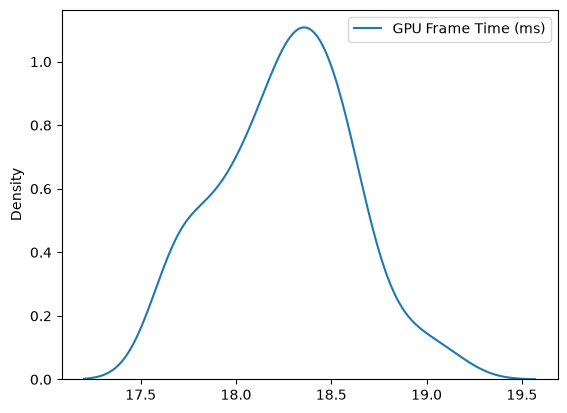

In [95]:
test_path = Path("../data/BASE/FRAME.xls")
test_df = pd.read_csv(test_path, sep="\t", header=None)
test_df = test_df.T.drop(0).rename(columns={0: "GPU Frame Time (ms)"})
sns.kdeplot(test_df)

In [146]:
for p in all_paths:
    print(p.name)
    test_df = pd.read_csv(p, sep="\t", header=None)
    print("N ROWS: ", len(test_df), ", N COLS: ", len(test_df.columns))
    print(test_df.head())
    print("-----------------------")

REPRO_INFO.xls
N ROWS:  34 , N COLS:  2
                        0                                                  1
0           Computer Name                                       ChunkyKongSr
1        Operating System                                 Linux (Arch Linux)
2  Operating System Build  #1 SMP PREEMPT_DYNAMIC Sat, 23 May 2026 14:21:...
3               Processor           Intel(R) Core(TM) i9-9900K CPU @ 3.60GHz
4               RAM Usage                      42134 MiB / 48085 MiB (87.6%)
-----------------------
D3DPERF_EVENTS.xls
N ROWS:  1 , N COLS:  61
           0        1        2        3        4        5        6        7   \
0  event_text  time_ms  time_ms  time_ms  time_ms  time_ms  time_ms  time_ms   

        8        9   ...       51       52       53       54       55  \
0  time_ms  time_ms  ...  time_ms  time_ms  time_ms  time_ms  time_ms   

        56       57       58       59       60  
0  time_ms  time_ms  time_ms  time_ms  time_ms  

[1 rows x 61 columns]
-

In [145]:
test_path = Path("../data/BASE/GPUTRACE_REGIMES.xls")
test_df = pd.read_csv(test_path, sep="\t")
test_df.head()

,flattened_event_name,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.1,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.2,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.3,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.4,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.5,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.6,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.7,FE_A.TriageSCG.gr__cycles_active.avg.pct_of_peak_sustained_elapsed.8,...,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.50,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.51,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.52,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.53,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.54,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.55,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.56,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.57,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.58,SM_A.TriageSCG.l1tex__data_pipe_lsu_wavefronts_mem_surface_realtime.avg.pct_of_peak_sustained_elapsed.59


In [129]:
test_df[[col for col in test_df.columns if "warp" in col]]

,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.1,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.2,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.3,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.4,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.5,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.6,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.7,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.8,SM_B.TriageSCG.tpc__warps_active_shader_vtg_realtime.avg.per_cycle_elapsed.9,...,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.50,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.51,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.52,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.53,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.54,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.55,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.56,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.57,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.58,TriageSCG.tpc__warps_inactive_sm_active_realtime.avg.pct_of_peak_sustained_elapsed.59


# Explore

In [57]:
frame_times = (df[df.Description.str.startswith("Frame")]["GPU Duration (ns)"]) / 1_000_000


<Axes: xlabel='GPU Duration (ns)', ylabel='Density'>

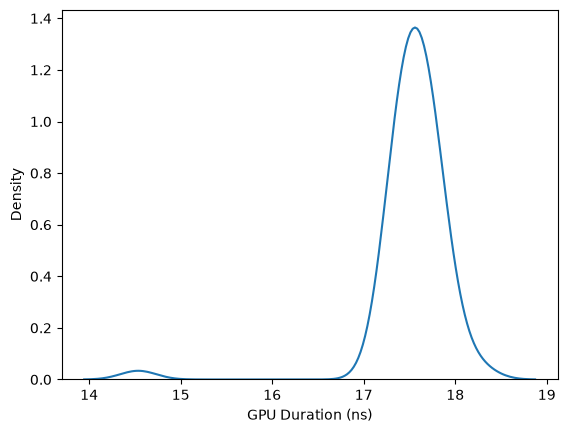

In [58]:
sns.kdeplot(frame_times)

In [59]:
frame_times = frame_times[frame_times > 17]

<Axes: xlabel='GPU Duration (ns)', ylabel='Density'>

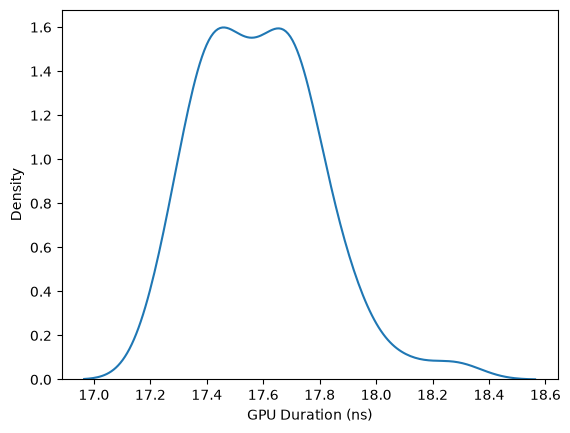

In [60]:
sns.kdeplot(frame_times)

In [65]:
mean_frame_time = frame_times.mean()
two_sigma_frame_time = frame_times.std() * 2

fpss = (frame_times / 1000) ** -1
mean_fps =  fpss.mean()
two_sigma_fps = fpss.std() * 2

print("FRAME TIME")
print(f"{mean_frame_time:.2f} +/- {two_sigma_frame_time:.2f} ms")
print(f"{frame_times.min():.2f} -> {frame_times.max():.2f}")

print()
print("FPS")
print(f"{mean_fps:.2f} +/- {two_sigma_fps:.2f} fps")

FRAME TIME
17.59 +/- 0.42 ms
17.25 -> 18.28

FPS
56.87 +/- 1.36 fps


<Axes: >

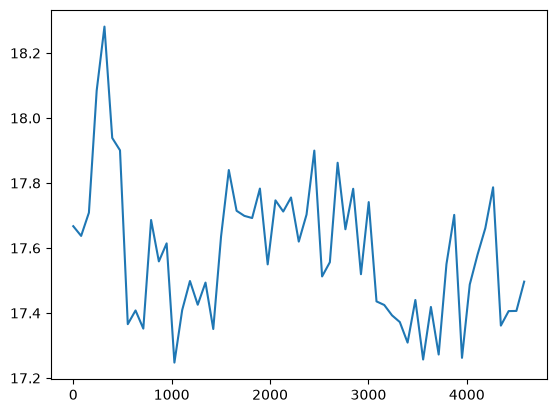

In [66]:
frame_times.plot()